In [74]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import trange, tqdm
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoImageProcessor
from itertools import islice
from collections import defaultdict
import matplotlib.pyplot as plt
import cv2

device = "cuda" if torch.cuda.is_available() else "cpu"

# paths
DATASET_ROOT = Path("../data/dataset-91591373-2402-4745-8455-4adc2690d0d5")
IMAGE_DIR = DATASET_ROOT / "images"
LABEL_DIR = DATASET_ROOT / "labels"
CLASS_NAMES = ["cluster", "trunk"]

In [85]:
trunk_bases = []
trunk_areas = []
trunk_x_centers = []
trunk_y_centers = []
trunk_boxes = []

image_paths = [
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
]
# for p in islice(image_paths, 3):
for p in tqdm(image_paths):
	image = cv2.imread(str(p))
	if image is None:
		print(f"Could not read {p}")
		continue

	# Convert BGR (OpenCV) to RGB (Matplotlib)
	image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
	h, w = image.shape[:2]
	# Find corresponding label file
	label_path = LABEL_DIR / f"{p.stem}.txt"

	if label_path.exists():
		with open(label_path, "r") as f:
			for line in f:
				parts = line.strip().split()
				if len(parts) < 5:
					continue

				class_id = int(parts[0])
				# only get trunks
				if class_id != 1:
					continue
				print(p)
				xc, yc, bw, bh = map(float, parts[1:5])
				# Convert normalized YOLO coordinates to pixels
				x1 = int((xc - bw / 2) * w)
				y1 = int((yc - bh / 2) * h)
				x2 = int((xc + bw / 2) * w)
				y2 = int((yc + bh / 2) * h)

				# Keep coordinates inside the image
				x1, x2 = max(0, x1), min(w - 1, x2)
				y1, y2 = max(0, y1), min(h - 1, y2)
				# calculate area
				box_width = x2 - x1
				box_height = y2 - y1
				area = box_width * box_height

				trunk_boxes.append({
					"image_path": str(p),
					"class_id": class_id,
					"x1": x1,
					"y1": y1,
					"x2": x2,
					"y2": y2,
					"base_y": y2,
					"x_center": (x1 + x2) / 2,
					"y_center": (y1 + y2) / 2,
					"area": area,
				})

				trunk_bases.append(y2)
				trunk_x_centers.append((x1 + x2) / 2)
				trunk_y_centers.append((y1 + y2) / 2)
				trunk_areas.append(area)
				# color = (0, 255, 0)
				# # Draw bounding box
				# cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
				# # Draw class label
				# name = (CLASS_NAMES[class_id] if 0 <= class_id < len(CLASS_NAMES) else str(class_id))
				# cv2.putText(image, name, (x1, max(20, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
	else:
		print(f"No label file found: {label_path}")

	# # Display image
	# plt.figure(figsize=(12, 8))
	# plt.imshow(image)
	# plt.axis("off")
	# plt.title(p.name)
	# plt.show()

  4%|▎         | 16/438 [00:00<00:05, 75.26it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0017607.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0007012.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0007012.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0022772.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0000224.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0000224.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0000224.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0010486.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0010486.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0010486.jpg
../data/dataset-91591373-2402-

  8%|▊         | 33/438 [00:00<00:05, 78.66it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0026944.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0026944.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0017084.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0017084.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0017084.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0008902.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0025859.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0025859.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0025859.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0025859.jpg
../data/dataset-91591373-2402-

 12%|█▏        | 51/438 [00:00<00:04, 83.06it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0031982.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0031982.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0031982.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0002471.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0002471.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0002471.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0002471.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0009759.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0009759.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0009759.jpg
../data/dataset-91591373-2402-

 14%|█▍        | 61/438 [00:00<00:04, 85.81it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0012066.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0012066.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0009061.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0003606.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0003606.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0003759.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0033612.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0039300.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0012217.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0012217.jpg
../data/dataset-91591373-2402-

 18%|█▊        | 79/438 [00:00<00:04, 83.00it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0033214.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0033214.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0035761.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0035761.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0035761.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0035761.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0035761.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0039302.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0039302.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0039302.jpg
../data/dataset-91591373-2402-

 20%|██        | 88/438 [00:01<00:04, 81.50it/s]

 22%|██▏       | 97/438 [00:01<00:04, 79.27it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0032600.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0013276.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0013276.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0039992.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0039992.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0039992.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0039992.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0039992.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0040602.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0040602.jpg
../data/dataset-91591373-2402-

 26%|██▋       | 115/438 [00:01<00:04, 80.49it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0004768.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0004768.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0004768.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0031599.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0031599.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0031599.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0006109.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0006109.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0023306.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0003278.jpg
../data/dataset-91591373-2402-

 30%|███       | 133/438 [00:01<00:03, 81.80it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0038975.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0038975.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0027811.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0027811.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0027811.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0027811.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0027811.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0027811.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0041401.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0041401.jpg
../data/dataset-91591373-2402-

 34%|███▍      | 151/438 [00:01<00:03, 81.17it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0028207.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0028207.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0028207.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0028207.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0028207.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0028207.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0027434.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0027434.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0027434.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0027434.jpg
../data/dataset-91591373-2402-

 39%|███▊      | 169/438 [00:02<00:03, 81.51it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0024516.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0024516.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0024516.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0041801.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0041801.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0016909.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0016909.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0016909.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0016909.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0021938.jpg
../data/dataset-91591373-2402-

 42%|████▏     | 186/438 [00:02<00:03, 79.32it/s]

../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0030298.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0030298.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0030298.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0030298.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0009586.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0029315.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0029315.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0029315.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_R_frame_0029315.jpg
../data/dataset-91591373-2402-4745-8455-4adc2690d0d5/images/1782121838_p0000_L_frame_0044367.jpg
../data/dataset-91591373-2402-

 43%|████▎     | 187/438 [00:02<00:03, 80.03it/s]


KeyboardInterrupt: 

In [3]:
IMG_H = 2048
IMG_W = 1536
trunk_bases = np.array(trunk_bases)
trunk_areas = np.array(trunk_areas)
trunk_y_centers = np.array(trunk_y_centers)
trunk_x_centers = np.array(trunk_x_centers)

bin_edges = np.arange(IMG_H + 1)
hist, bin_edges = np.histogram(trunk_bases, bins=bin_edges, range=(0, IMG_H+1))

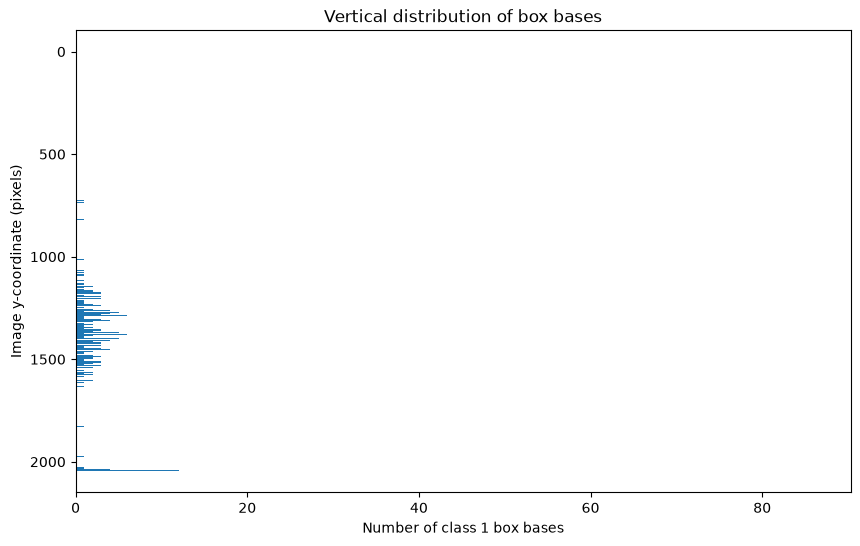

In [66]:
plt.figure(figsize=(10, 6))
plt.barh(bin_edges[:-1], hist, height=1.0)

plt.gca().invert_yaxis()  # y=0 at the top
plt.xlabel("Number of class 1 box bases")
plt.ylabel("Image y-coordinate (pixels)")
plt.title("Vertical distribution of box bases")
plt.show()

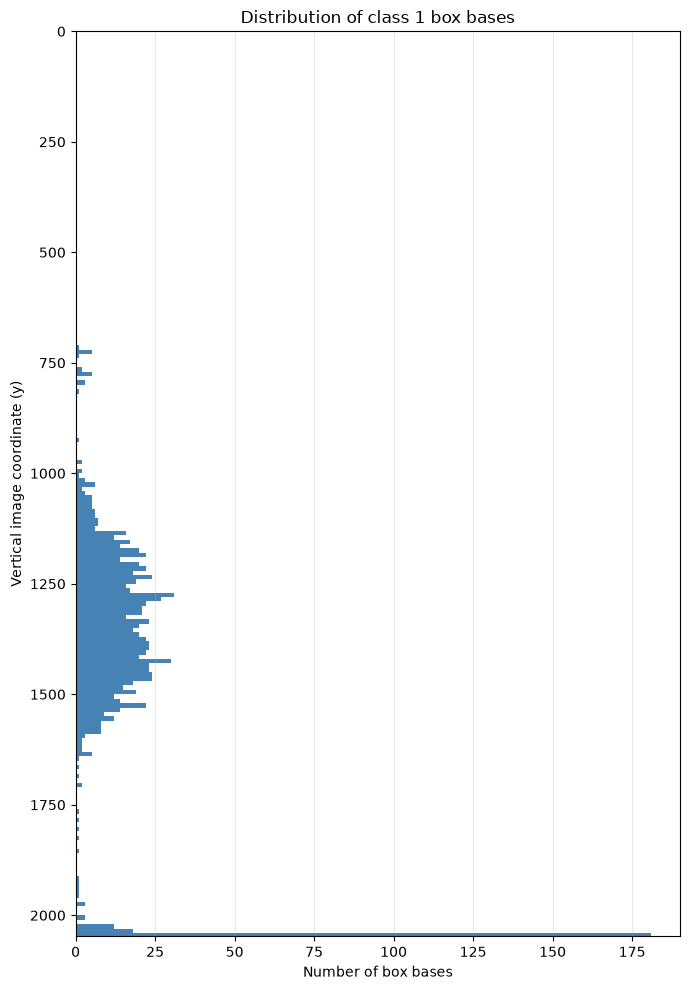

In [47]:
trunk_bases = np.asarray(trunk_bases)

# One bin per 10 pixels (adjust as needed)
bin_width = 10
bins = np.arange(0, IMG_H + bin_width, bin_width)

hist, edges = np.histogram(trunk_bases, bins=bins)

fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(edges[:-1], hist, height=bin_width, align="edge", color="steelblue", edgecolor="none")

ax.set_ylim(IMG_H, 0)  # Image coordinates: 0 at top
ax.set_xlabel("Number of box bases")
ax.set_ylabel("Vertical image coordinate (y)")
ax.set_title("Distribution of class 1 box bases")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


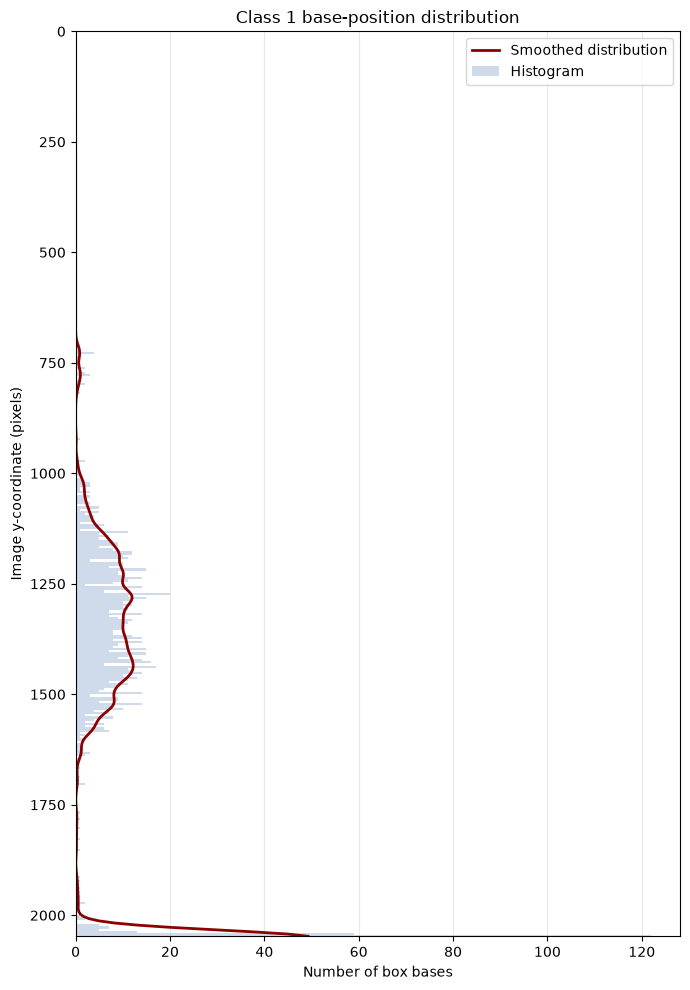

In [69]:
from scipy.ndimage import gaussian_filter1d
trunk_bases = np.asarray(trunk_bases)
bin_width = 5
bins = np.arange(0, IMG_H + bin_width, bin_width)

hist, edges = np.histogram(trunk_bases, bins=bins)
centers = (edges[:-1] + edges[1:]) / 2

# Smooth the histogram
smooth_hist = gaussian_filter1d(hist.astype(float), sigma=3)

fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(centers, hist, height=bin_width, color="lightsteelblue", alpha=0.6, label="Histogram")

ax.plot(smooth_hist, centers, color="darkred", linewidth=2, label="Smoothed distribution")

ax.set_ylim(IMG_H, 0)
ax.set_xlabel("Number of box bases")
ax.set_ylabel("Image y-coordinate (pixels)")
ax.set_title("Class 1 base-position distribution")
ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

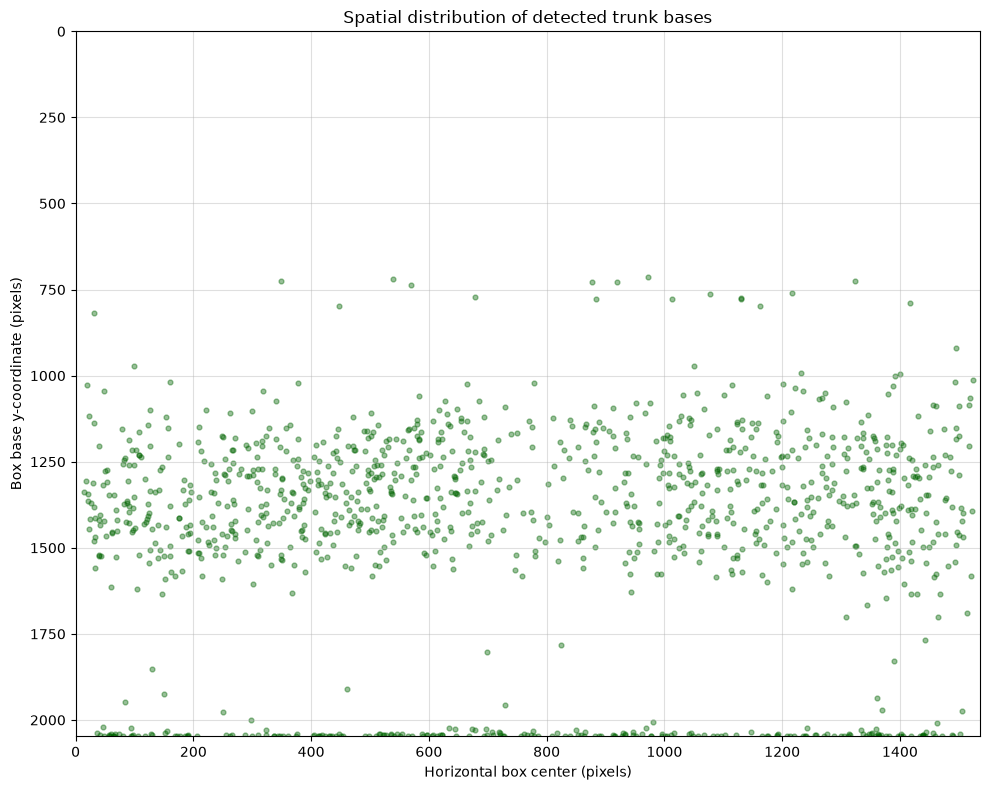

In [70]:
IMG_H = 2048
IMG_W = 1536
x = np.asarray(trunk_x_centers)
y = np.asarray(trunk_bases)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(x, y, s=12, alpha=0.4, color="darkgreen")

ax.set_xlim(0, IMG_W)  # Replace with your actual image width
ax.set_ylim(IMG_H, 0)  # Image coordinates: origin at top
ax.set_xlabel("Horizontal box center (pixels)")
ax.set_ylabel("Box base y-coordinate (pixels)")
ax.set_title("Spatial distribution of detected trunk bases")
ax.grid(alpha=0.4)

plt.tight_layout()
plt.show()

(1194, 2)
[ 762.75263158 1335.20631579]
[ 776.09502262 2040.06334842]


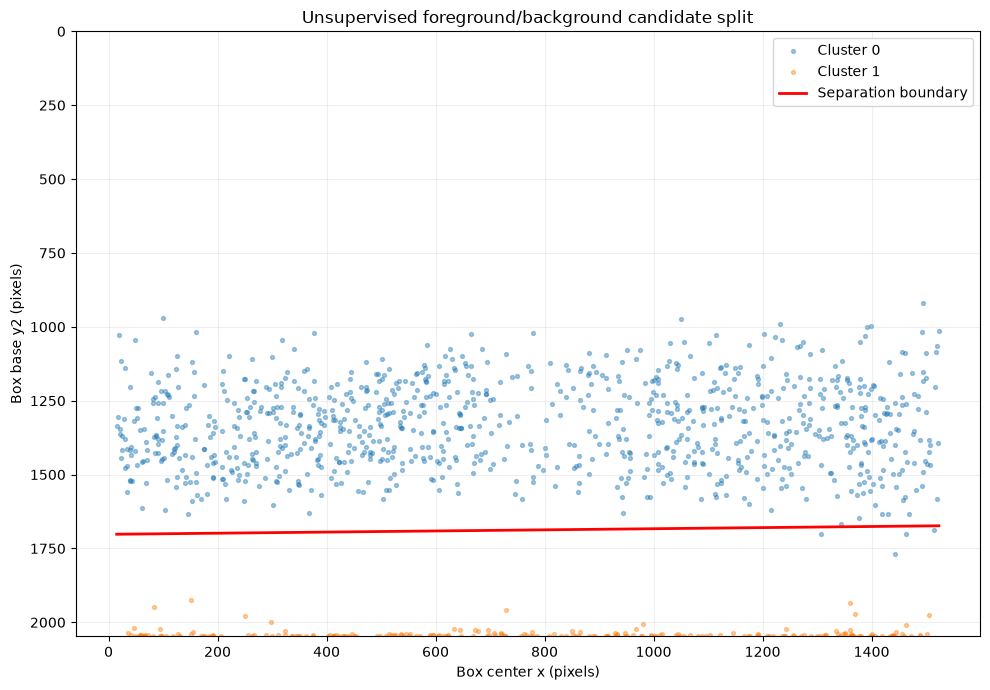

In [88]:
# clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN

X = np.column_stack([trunk_x_centers, trunk_bases ]).astype(float)

scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)
print(X.shape)
# Cluster into two geometric groups
# kmeans = KMeans(n_clusters=2, n_init=20, random_state=42)
# labels = kmeans.fit_predict(X)
# c0, c1 = kmeans.cluster_centers_
dbscan = DBSCAN(eps=100)
labels = dbscan.fit_predict(X)

# TODO: Fix this DUMMY/copy paste centroid calculation
points_of_cluster_0 = X[labels==0,:]
c0 = np.mean(points_of_cluster_0, axis=0) 
print(c0)

points_of_cluster_1 = X[labels==1,:]
c1 = np.mean(points_of_cluster_1, axis=0)
print(c1)

# Equation of perpendicular bisector: (c1 - c0) dot p = (||c1||² - ||c0||²) / 2
delta = c1 - c0
rhs = (c1 @ c1 - c0 @ c0) / 2

# Plot the clusters and their separation line
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(X[labels == 0, 0], X[labels == 0, 1], s=8, alpha=0.4, label="Cluster 0")
ax.scatter(X[labels == 1, 0], X[labels == 1, 1], s=8, alpha=0.4, label="Cluster 1")

xx = np.linspace(X[:, 0].min(), X[:, 0].max(), 300)

if abs(delta[1]) > 1e-8:
    yy = (rhs - delta[0] * xx) / delta[1]
    ax.plot(xx, yy, "r-", linewidth=2, label="Separation boundary")

ax.set_xlabel("Box center x (pixels)")
ax.set_ylabel("Box base y2 (pixels)")
ax.set_title("Unsupervised foreground/background candidate split")
ax.set_ylim(2048, 0)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# print("Cluster centers (x, y):", c0, c1)

In [4]:
max(trunk_areas)

np.int64(519662)

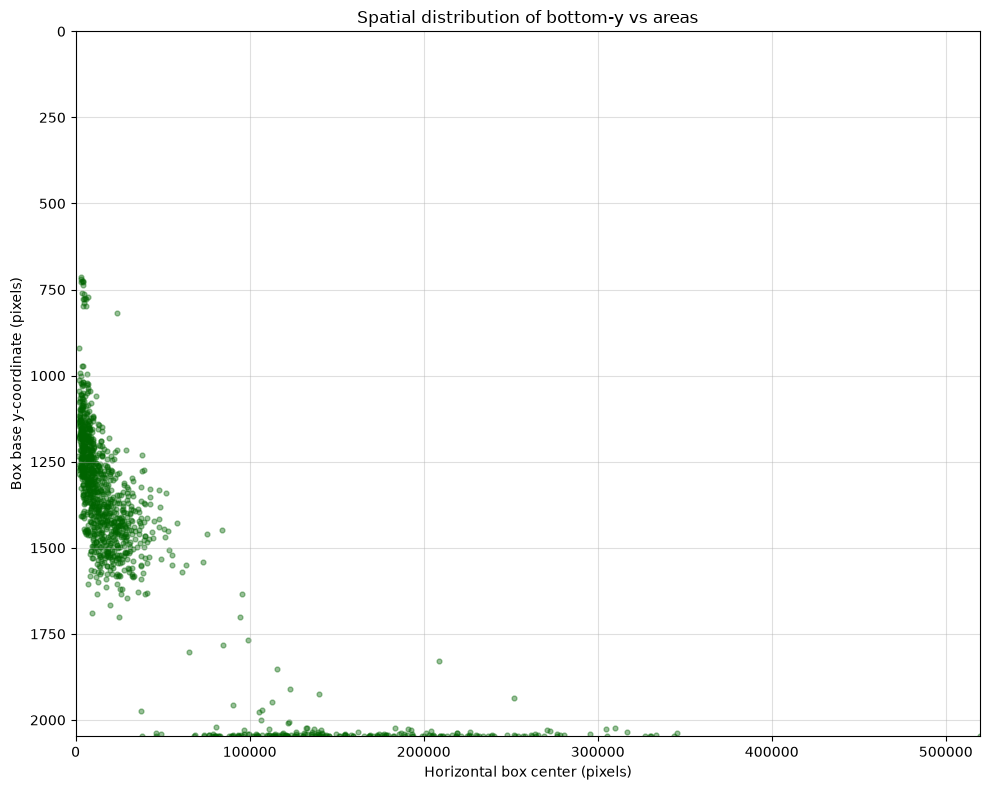

In [ ]:
# Box Area analysis
IMG_H = 2048
IMG_W = 1536
x = np.asarray(trunk_areas)
y = np.asarray(trunk_bases)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(x, y, s=12, alpha=0.4, color="darkgreen")

ax.set_xlim(0, trunk_areas.max()) 
ax.set_ylim(IMG_H, 0)  # Image coordinates: origin at top
ax.set_xlabel("Area (pixels)")
ax.set_ylabel("Box base y-coordinate (pixels)")
ax.set_title("Spatial distribution of bottom-y vs areas")
ax.grid(alpha=0.4)

plt.tight_layout()
plt.show()

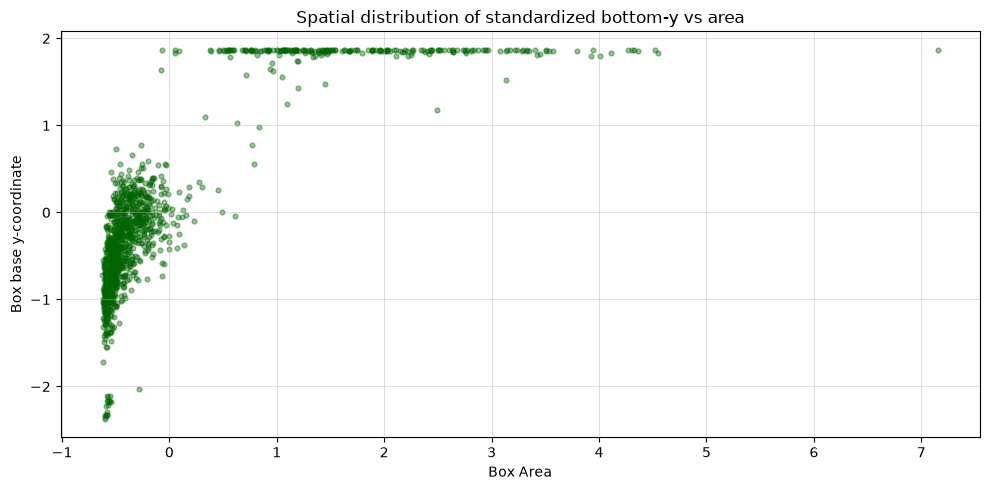

In [81]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

df = pd.DataFrame(trunk_boxes)
# Choose the features used for clustering
features = ["area", "base_y"]
X = df[features]#.to_numpy(dtype=np.float32)

scaler = StandardScaler()
X_stand = scaler.fit_transform(X)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X_stand[:, 0], X_stand[:, 1], s=12, alpha=0.4, color="darkgreen")

# NOTE: plot on the same axis the standardized data
# ax.set_xlim(0, X_stand[:,1].max()) 
# ax.set_ylim(X_stand[:, 0].max(), 0)
ax.set_xlabel("Box Area")
ax.set_ylabel("Box base y-coordinate")
ax.set_title("Spatial distribution of standardized bottom-y vs area")
ax.grid(alpha=0.4)

plt.tight_layout()
plt.show()

In [82]:
kmeans = KMeans(n_clusters=2, n_init=20, random_state=42)
labels = kmeans.fit_predict(X_stand)
df["cluster"] = kmeans.fit_predict(X_stand)

df.head()

,image_path,class_id,x1,y1,x2,y2,base_y,x_center,y_center,area,cluster
0,../data/dataset-91591373-2402-4745-8455-4adc26...,1,906,1014,959,1282,1282,932.5,1148.0,14204,0
1,../data/dataset-91591373-2402-4745-8455-4adc26...,1,1,910,38,1027,1027,19.5,968.5,4329,0
2,../data/dataset-91591373-2402-4745-8455-4adc26...,1,78,876,122,971,971,100.0,923.5,4180,0
3,../data/dataset-91591373-2402-4745-8455-4adc26...,1,634,948,704,1244,1244,669.0,1096.0,20720,0
4,../data/dataset-91591373-2402-4745-8455-4adc26...,1,40,1212,221,1851,1851,130.5,1531.5,115659,1


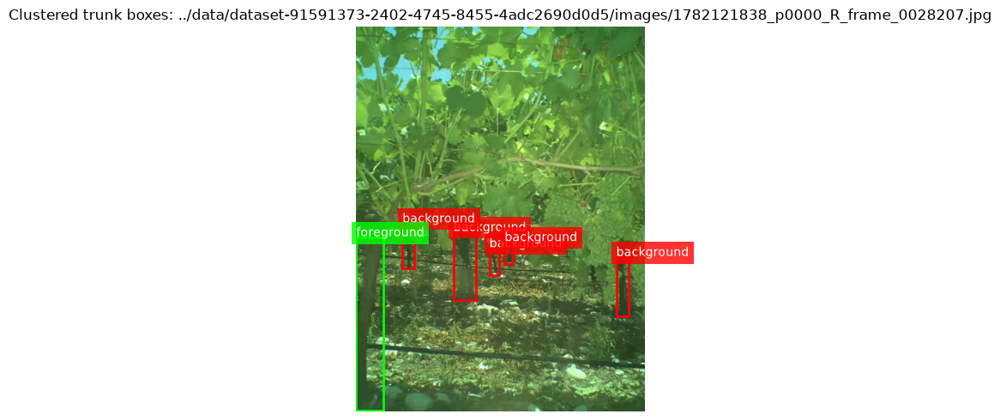

In [105]:
# plot trunks based on clusters
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

cluster_map = {0:"background", 1: "foreground"}

def show_clustered_image(image_path, df):
    image = cv2.imread(str(image_path))

    if image is None:
        print(f"Could not read {image_path}")
        return

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(image)

    # Get detections belonging to this image
    boxes = df[df["image_path"] == str(image_path)]

    colors = {0: "red", 1: "lime"}

    for _, row in boxes.iterrows():
        color = colors[row["cluster"]]

        rect = patches.Rectangle((row["x1"], row["y1"]), row["x2"] - row["x1"], row["y2"] - row["y1"],
            linewidth=2, edgecolor=color, facecolor="none")
        ax.add_patch(rect)
        ax.text(row["x1"], max(0, row["y1"] - 5), f"{cluster_map[row['cluster']]}", color="white", fontsize=10, bbox=dict(facecolor=color, alpha=0.8, edgecolor="none"))

    ax.set_title(f"Clustered trunk boxes: {image_path}")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

show_clustered_image(IMAGE_DIR / "1782121838_p0000_R_frame_0028207.jpg", df)

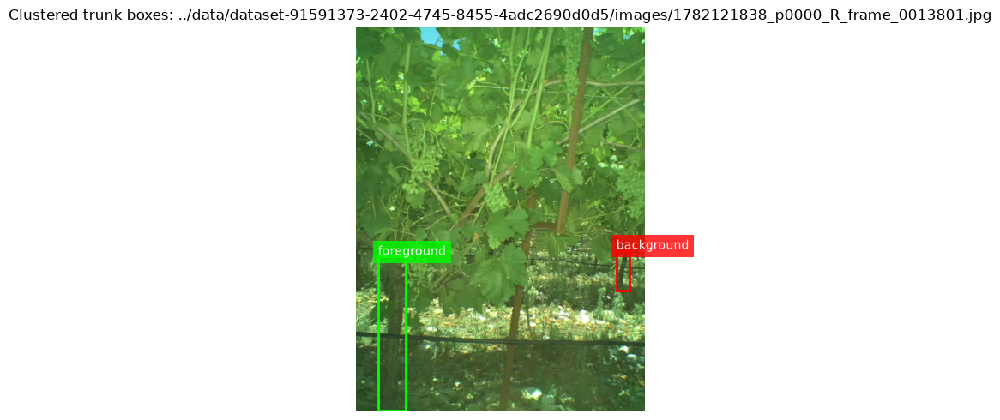

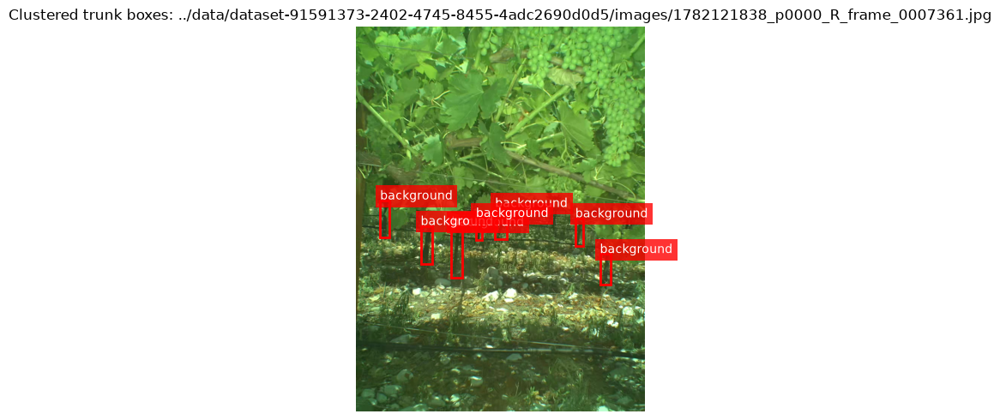

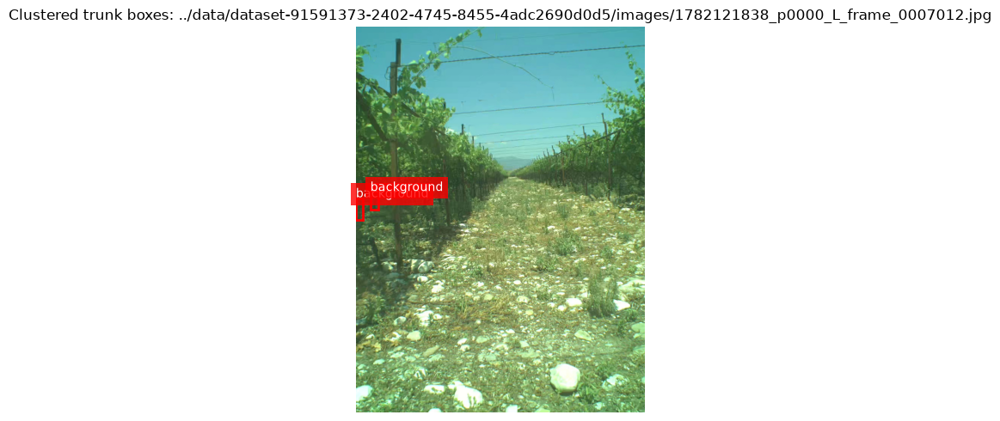

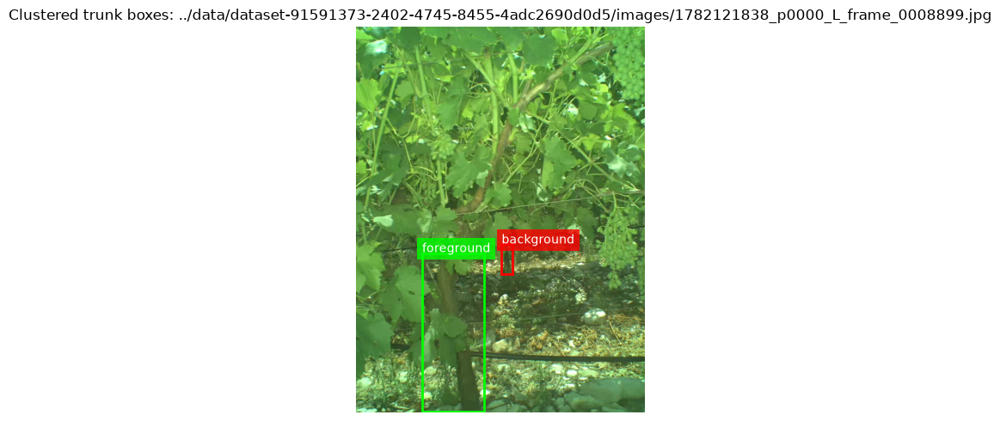

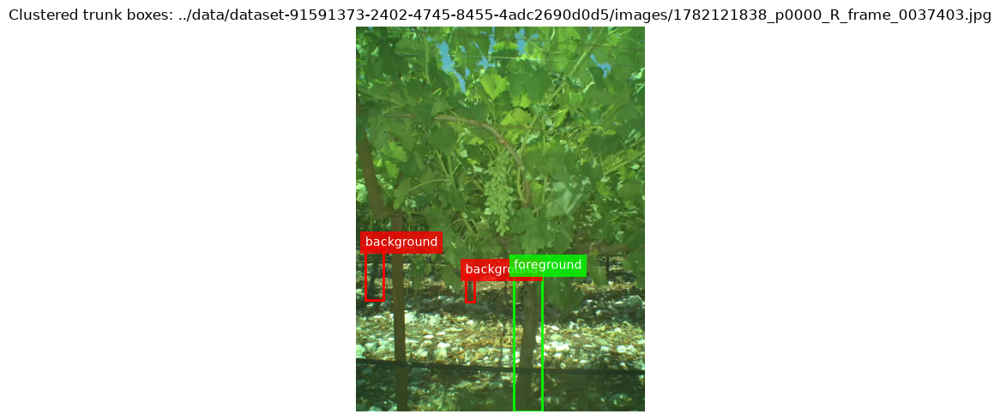

...

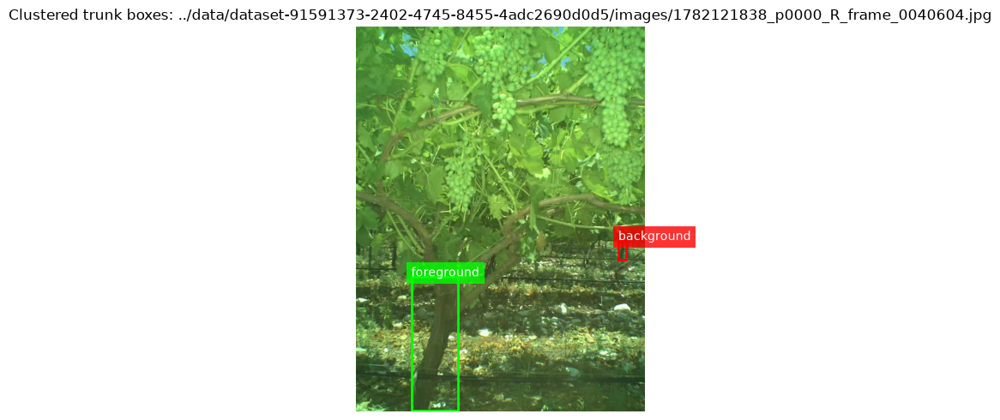

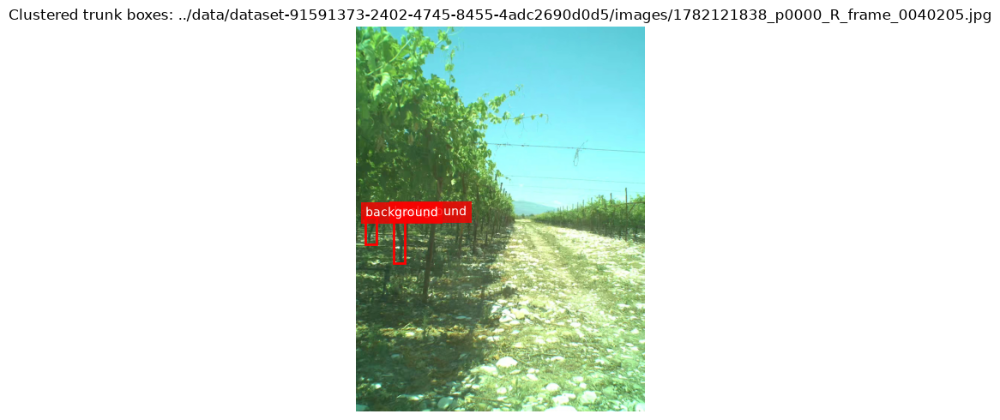

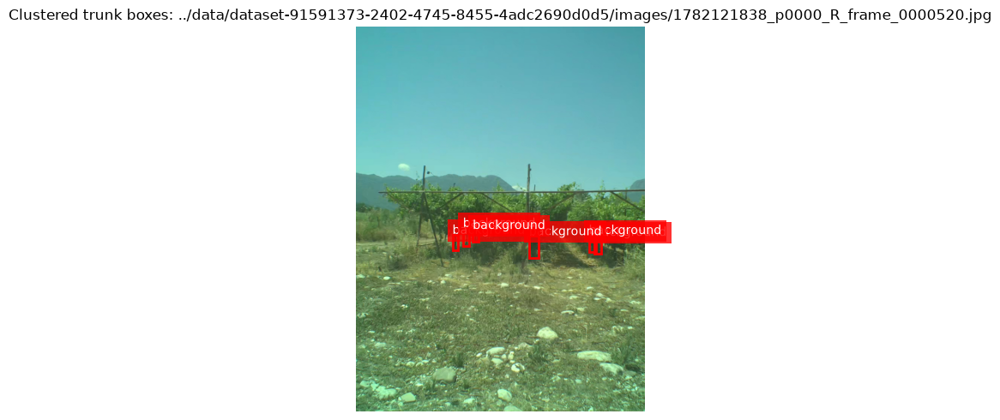

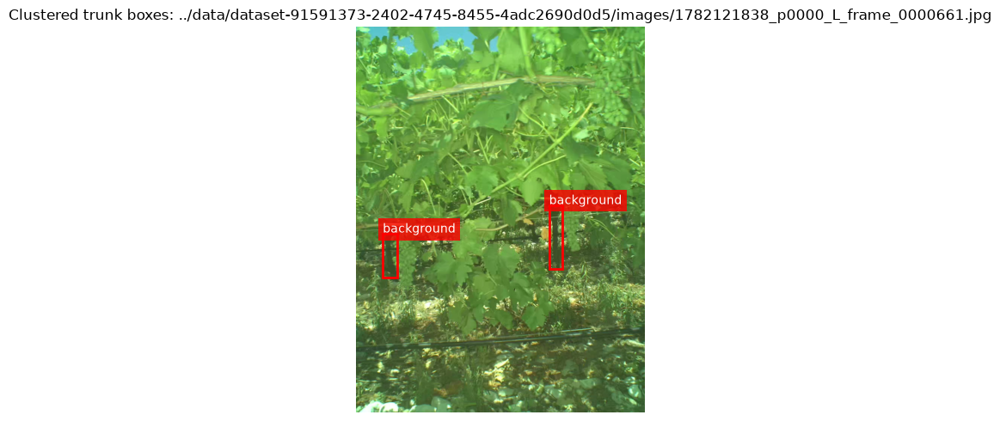

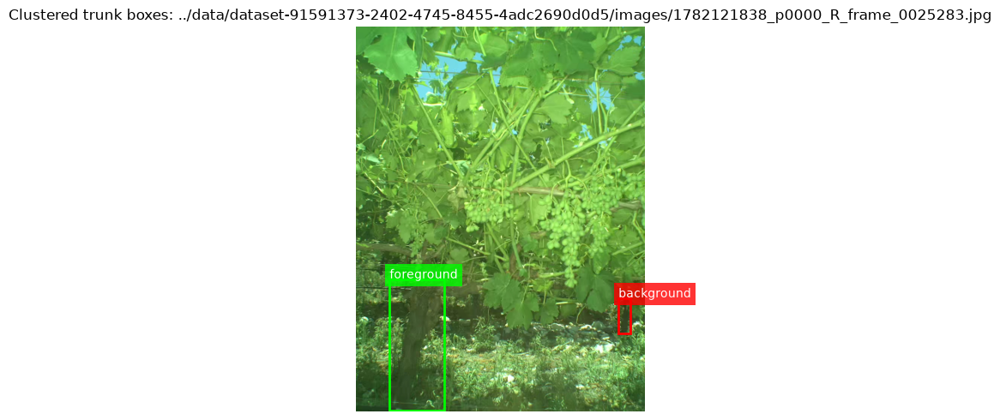

In [106]:
import random
images_with_boxes = df["image_path"].unique().tolist()

for image_path in random.sample(images_with_boxes, k=min(20, len(images_with_boxes))):
    show_clustered_image(image_path, df)

519662.0 7.157198816338845


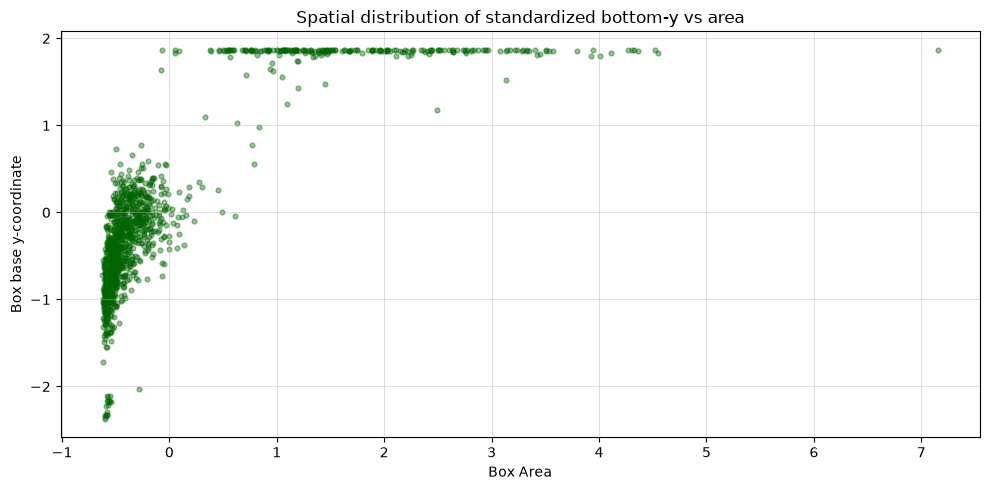

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

scaler = StandardScaler()
X = np.column_stack([trunk_bases, trunk_areas]).astype(float)
X_stand = scaler.fit_transform(X)

print(X.max(), X_stand.max())

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X_stand[:, 1], X_stand[:, 0], s=12, alpha=0.4, color="darkgreen")

# NOTE: plot on the same axis the standardized data
# ax.set_xlim(0, X_stand[:,1].max()) 
# ax.set_ylim(X_stand[:, 0].max(), 0)
ax.set_xlabel("Box Area")
ax.set_ylabel("Box base y-coordinate")
ax.set_title("Spatial distribution of standardized bottom-y vs area")
ax.grid(alpha=0.4)

plt.tight_layout()
plt.show()


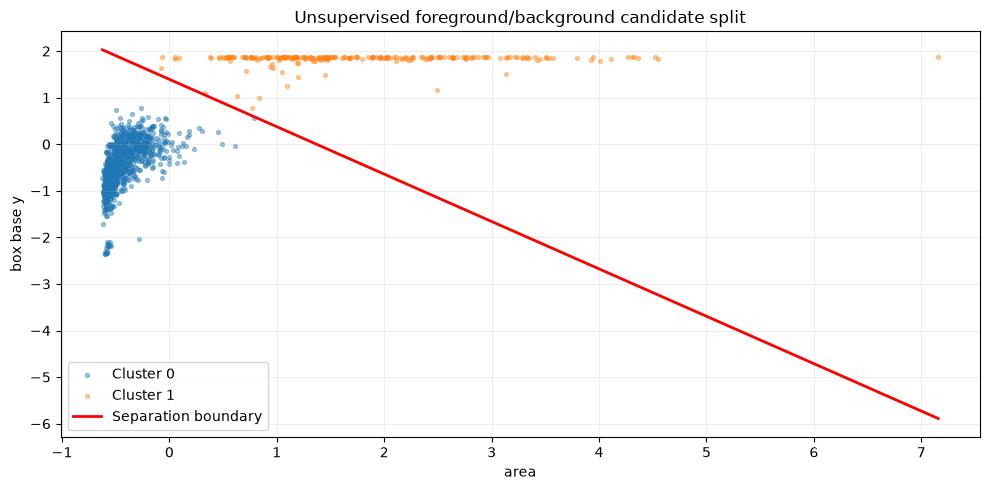

In [67]:
# to get right number of clusters
# for k in range(2, 7):
#     kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
#     labels = kmeans.fit_predict(X_stand)
#     score = silhouette_score(X_stand, labels)
#     print(k, score)

kmeans = KMeans(n_clusters=2, n_init=20, random_state=42)
labels = kmeans.fit_predict(X_stand)
c0, c1 = kmeans.cluster_centers_

# Equation of perpendicular bisector: (c1 - c0) dot p = (||c1||² - ||c0||²) / 2
delta = c1 - c0
rhs = (c1 @ c1 - c0 @ c0) / 2

# Plot the clusters and their separation line
fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(X_stand[labels == 0, 1], X_stand[labels == 0, 0], s=8, alpha=0.4, label="Cluster 0")
ax.scatter(X_stand[labels == 1, 1], X_stand[labels == 1, 0], s=8, alpha=0.4, label="Cluster 1")

xx = np.linspace(X_stand[:, 1].min(), X_stand[:, 1].max(), 300)

if abs(delta[1]) > 1e-8:
    yy = (rhs - delta[0] * xx) / delta[1]
    ax.plot(xx, yy, "r-", linewidth=2, label="Separation boundary")

ax.set_xlabel("area")
ax.set_ylabel("box base y")
ax.set_title("Unsupervised foreground/background candidate split")
# ax.set_ylim(2048, 0)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Centroid 0: [-0.39779014 -0.42273333]
Centroid 1: [1.84761955 1.78401865]


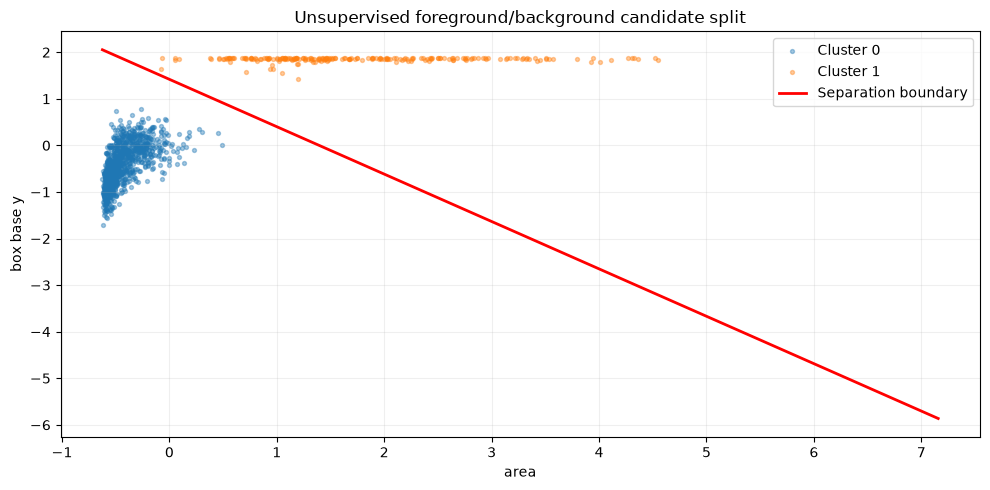

In [64]:
# DBSCAN on y_bottom-area
dbscan = DBSCAN(eps=0.3)
labels = dbscan.fit_predict(X_stand)

# TODO: Fix this DUMMY/copy paste centroid calculation
points_of_cluster_0 = X_stand[labels==0,:]
c0 = np.mean(points_of_cluster_0, axis=0) 
print(f"Centroid 0: {c0}")

points_of_cluster_1 = X_stand[labels==1,:]
c1 = np.mean(points_of_cluster_1, axis=0)
print(f"Centroid 1: {c1}")

# Equation of perpendicular bisector: (c1 - c0) dot p = (||c1||² - ||c0||²) / 2
delta = c1 - c0
rhs = (c1 @ c1 - c0 @ c0) / 2

# Plot the clusters and their separation line
fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(X_stand[labels == 0, 1], X_stand[labels == 0, 0], s=8, alpha=0.4, label="Cluster 0")
ax.scatter(X_stand[labels == 1, 1], X_stand[labels == 1, 0], s=8, alpha=0.4, label="Cluster 1")

xx = np.linspace(X_stand[:, 1].min(), X_stand[:, 1].max(), 300)

if abs(delta[1]) > 1e-8:
    yy = (rhs - delta[0] * xx) / delta[1]
    ax.plot(xx, yy, "r-", linewidth=2, label="Separation boundary")

ax.set_xlabel("area")
ax.set_ylabel("box base y")
ax.set_title("Unsupervised foreground/background candidate split")
# ax.set_ylim(2048, 0)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()